# NB1 · From tracks to kinematics, behavioral states and time-correlations

After processing experimental measurements into trajectories in space, a natural step is to analyze the dynamics and patterns of navigation data. We can first compute the kinematics, namely the forward velocity and the angular velocity.
As described in the lecture, one can analyze the patterns of the velocity time series to discover that *E. coli* alternates between **runs** (swimming nearly straight) and **tumbles** (a short, slow, random reorientation). These are its **behavioral states**. How a cell combines its states, and how it changes its runs and tumbles in response to the sensory environment (such as a chemical gradient), is its **navigation strategy**. Strategies differ **between species** (some bacteria reverse instead of tumbling) and even **between individuals** of one species.

To see any of this in data, we first need to turn positions into quantities that describe behavior. In this notebook:

* **A · Speeds.** From positions to velocity, speed and angular velocity, and how localization noise and smoothing affect them (with the interactive smoothing explorer).
* **B · State space.** Runs and tumbles then appear as separate regions in the plane of speed $v$ and angular velocity $\omega$.
* **C · Correlations.** How long a cell remembers its velocity and its direction.

(Part **D**, from kinematics back to tracks in space, is shown in the mean squared displacement analysis in NB2.)

**Data.** One synthetic dataset, `run_tumble`: tracks of *E. coli*-like run-and-tumble swimmers that look like real microscopy data. They are recorded at 30 frames per second, every position has a localization error, and tracks are short because cells leave the focal plane. Because the data are synthetic, we also know the *true* state (run or tumble) of every cell in every frame, so we can check our methods. In part C we compare these cells with simulated cells whose tumble rate drifts over time.

Cells marked **🔧 Try it** are meant to be edited and re-run.

## 0 · Setup
Run this cell first. It loads the packages we use and the course package `motility`, which is in the folder above `notebooks/`. Use the kernel **Python (mcdb5910)** (see the README).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # the course package `motility` is in the folder above notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from motility import io, plotting
from motility import analysis as an
from motility import simulate as sim
from motility.plotting import COLORS, STYLE, GRAY, THEORY_KW

plotting.set_style()
rng = np.random.default_rng(5910)   # fixed seed: everyone gets the same figures

## 1 · The data

The dataset is a table with one row per detection: which cell (`track_id`), when (`frame`, and `t` in s), and where (`x_um`, `y_um` in µm). A JSON file holds the metadata: the frame rate, the localization noise, and the parameters used to simulate the cells. A second table, the **truth**, gives the true state of each detection.

In [2]:
df, meta = io.load_dataset("run_tumble")
truth = io.load_truth("run_tumble")
FPS = meta["fps"]                          # frames per second
SIGMA = meta["localization_noise_um"]      # µm, localization noise of every position

print(meta["description"])
print(f"{meta['n_tracks']} tracks, {len(df)} detections, {FPS:.0f} frames per second, "
      f"localization noise {SIGMA} µm")
df.head()

Run-and-tumble swimmers (E. coli-like) in a uniform environment. Each cell has its own swimming speed. Tumbles happen at a constant rate.
400 tracks, 123855 detections, 30 frames per second, localization noise 0.2 µm


,track_id,frame,t,x_um,y_um
0,1,248,8.2667,455.648,411.227
1,1,249,8.3000,456.176,410.757
2,1,250,8.3333,457.026,409.982
3,1,251,8.3667,457.667,409.748
4,1,252,8.4000,458.445,409.392


The cells were simulated with these parameters (in a real experiment we would not know them; here they let us check our results):

| parameter | meaning |
|---|---|
| `speed`, `speed_sd` | swimming speed (µm/s): each cell gets its own speed, mean `speed`, standard deviation `speed_sd` |
| `run_rate` | tumble rate (1/s): runs last on average 1/`run_rate` s |
| `tumble_time` | mean duration of a tumble (s) |
| `tumble_speed` | speed during a tumble, as a fraction of the cell's swimming speed |
| `turn_angle` | turn at a tumble: mean and standard deviation (degrees) |
| `Dr` | rotational diffusion during runs (rad²/s): the slow wobble of the swimming direction |

In [3]:
params = meta["model_parameters"]
pd.Series(params, name="value").to_frame()

,value
speed,25.0
speed_sd,4.0
run_rate,1.0
tumble_time,0.15
tumble_speed,0.2
turn_angle,"[68.0, 36.0]"
Dr,0.15


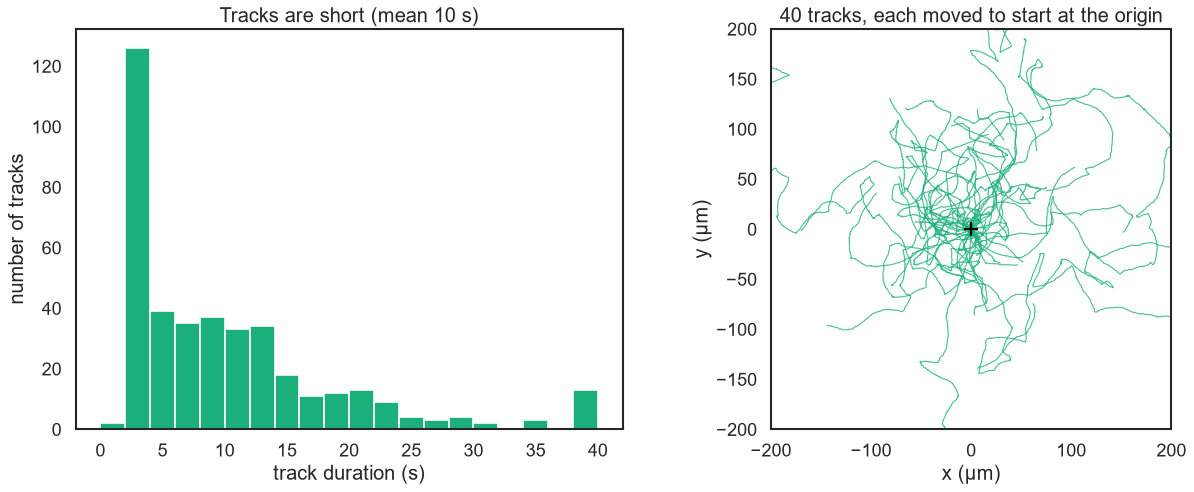

In [4]:
durations = df.groupby("track_id")["t"].agg(lambda t: t.max() - t.min())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5))
ax1.hist(durations, bins=np.arange(0, 42, 2), color=COLORS["run_tumble"])
ax1.set(xlabel="track duration (s)", ylabel="number of tracks",
        title=f"Tracks are short (mean {durations.mean():.0f} s)")

for tid, g in list(df.groupby("track_id"))[:40]:
    xy = g[["x_um", "y_um"]].to_numpy()
    ax2.plot(xy[:, 0] - xy[0, 0], xy[:, 1] - xy[0, 1], color=COLORS["run_tumble"], lw=1, alpha=0.8)
ax2.plot(0, 0, "+", color="k", ms=12, mew=2)
ax2.set(xlim=(-200, 200), ylim=(-200, 200), aspect="equal", xlabel="x (µm)", ylabel="y (µm)",
        title="40 tracks, each moved to start at the origin")
fig.tight_layout()
plt.show()

## 2 · A · Speeds

### 2.1 Velocity from noisy positions
The simplest velocity estimate is the displacement between consecutive frames divided by the time between them:
$$\mathbf v_n=\frac{\mathbf r_{n+1}-\mathbf r_n}{\Delta t},\qquad \Delta t=\frac{1}{\text{fps}},\qquad v_n=|\mathbf v_n|\ \ \text{(the speed)}.$$
But every detected position has an error of about $\sigma=0.2$ µm (a cell is only a few pixels wide). The difference of two positions has an error $\sqrt2\,\sigma$, and dividing by $\Delta t=1/30$ s multiplies it by 30. Each velocity component therefore gets a noise $\sigma_v=\sqrt2\,\sigma/\Delta t\approx8.5$ µm/s, about a third of the swimming speed.

To reduce the noise we estimate the velocity from several frames at once with a **Savitzky–Golay filter**: it fits a parabola to the positions in a window of $w$ frames around each frame and takes the slope of the parabola at the center. A wider window removes more noise, but it also blurs events shorter than the window — and a tumble lasts only about 0.15 s, or 4–5 frames.

> **🖥 Smoothing explorer.** Open `notebooks/NB3_smoothing_explorer.html` in a web browser (no Python needed). Move the window slider and watch the speed of a swimming cell: short windows let the noise through, long windows fill in the tumbles. The lower chart shows the velocity error against the window length; the best window is where noise and blur balance. NB3 shows how the explorer is computed.

Here is the same trade-off on one cell of our dataset, the longest track. Gray bands mark the frames in which the cell is truly tumbling.

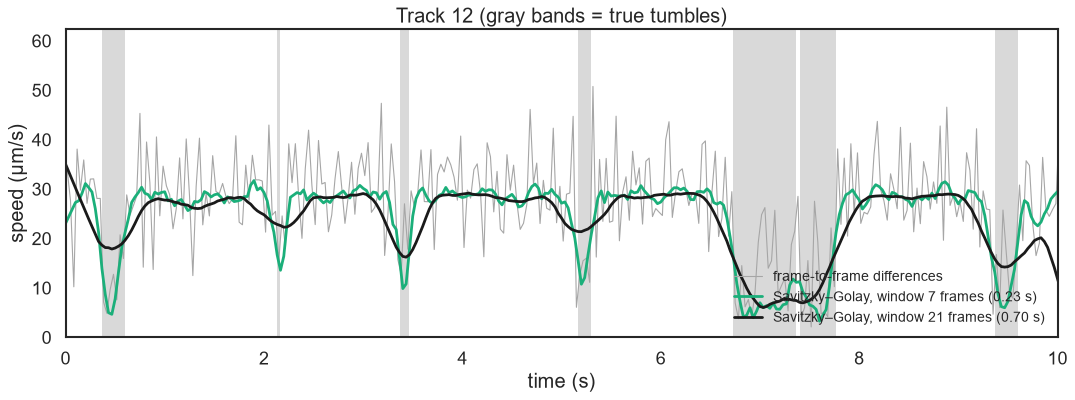

In [5]:
TID = durations.idxmax()                              # the longest track
one = df[df.track_id == TID].sort_values("frame")
t1 = one["t"].to_numpy() - one["t"].iloc[0]           # time since the start of the track (s)
tumbling1 = one.merge(truth, on=["track_id", "frame"])["state"].eq("tumble").to_numpy()

def shade_tumbles(ax, t, tumbling):
    """Draw gray bands where the cell is truly tumbling."""
    edges = np.diff(np.r_[0, tumbling.astype(int), 0])
    for start, stop in zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)):
        ax.axvspan(t[start], t[stop - 1] + 1 / FPS, color="0.85", lw=0, zorder=0)

xy1 = one[["x_um", "y_um"]].to_numpy()
speed_raw = np.hypot(*(np.diff(xy1, axis=0) * FPS).T)        # frame-to-frame speed (µm/s)

T_SHOW = 10                                           # s of the track to show
fig, ax = plt.subplots(figsize=(16, 5))
shade_tumbles(ax, t1, tumbling1)
ax.plot(t1[:-1] + 0.5 / FPS, speed_raw, color="0.65", lw=1, label="frame-to-frame differences")
for w, color in [(7, COLORS["run_tumble"]), (21, "0.1")]:
    k = an.kinematics(one, FPS, window=w)
    ax.plot(k["t"] - one["t"].iloc[0], k["speed"], color=color, lw=2.5, label=f"Savitzky–Golay, window {w} frames ({w / FPS:.2f} s)")
ax.set(xlim=(0, T_SHOW), ylim=(0, None), xlabel="time (s)", ylabel="speed (µm/s)",
       title=f"Track {TID} (gray bands = true tumbles)")
ax.legend(fontsize="x-small", loc="lower right")
plt.show()

We use a window of **7 frames (0.23 s)**, close to the best window the explorer finds for these settings. It brings the noise from 8.5 µm/s down to about 1 µm/s per velocity component, and a tumble still shows as a clear dip. `an.kinematics` computes the velocity, speed, heading and angular velocity of every frame of every track.

In [6]:
WINDOW = 7
kin = an.kinematics(df, FPS, window=WINDOW)           # velocity, speed, heading, angular velocity of every frame
kin = kin.merge(truth, on=["track_id", "frame"])      # add the true state (synthetic data only)
print(f"velocity noise per component: {an.velocity_noise(SIGMA, FPS):.1f} µm/s from frame-to-frame differences, "
      f"{an.velocity_noise(SIGMA, FPS, WINDOW):.1f} µm/s after smoothing")

kin.head()

velocity noise per component: 8.5 µm/s from frame-to-frame differences, 1.1 µm/s after smoothing


,track_id,frame,t,vx,vy,speed,heading,omega,state
0,1,248,8.2667,20.286429,-17.261786,26.636599,-0.705018,1.143327,run
1,1,249,8.3000,20.425000,-16.046786,25.974602,-0.665926,1.202348,run
2,1,250,8.3333,20.563571,-14.831786,25.354336,-0.624856,1.261896,run
3,1,251,8.3667,20.702143,-13.616786,24.778934,-0.581802,1.321182,run
4,1,252,8.4000,21.883929,-11.658214,24.795570,-0.489487,2.660985,run


### 2.2 Angular velocity
The **angular velocity** $\omega$ is how fast the swimming direction $\theta$ turns, $\omega=d\theta/dt$. From the smoothed velocity $\mathbf v$ and acceleration $\mathbf a$:
$$\omega=\frac{v_x a_y-v_y a_x}{|\mathbf v|^2}\quad(\text{rad/s}).$$

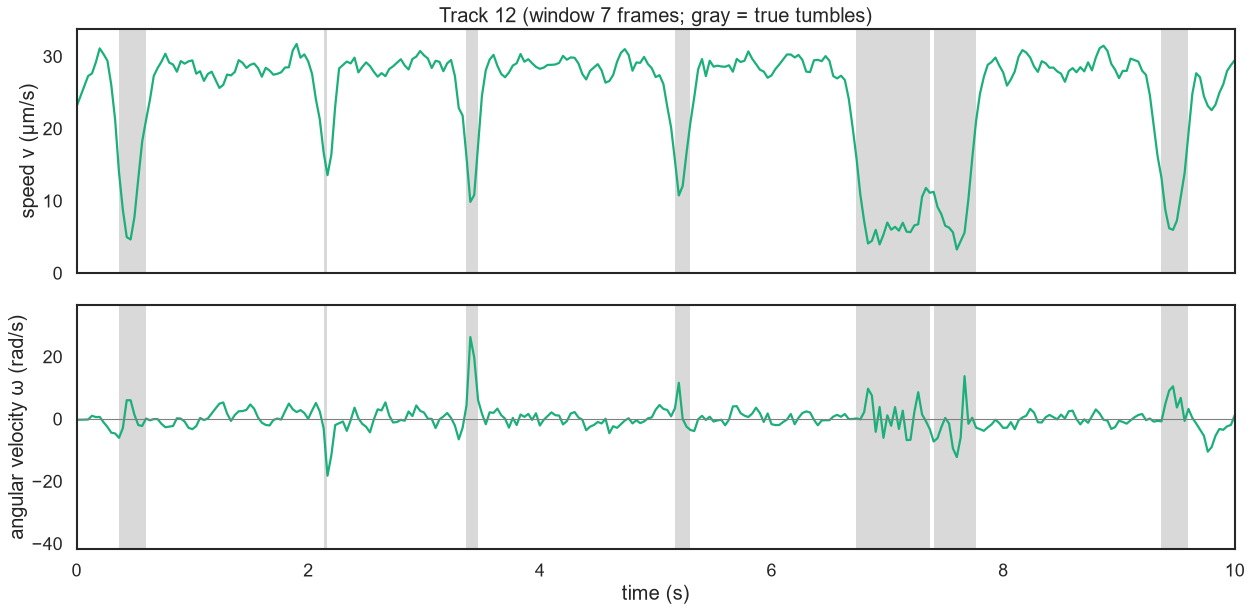

In [7]:
k1 = kin[kin.track_id == TID]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
for ax in (ax1, ax2):
    shade_tumbles(ax, t1, tumbling1)
ax1.plot(k1["t"] - one["t"].iloc[0], k1["speed"], color=COLORS["run_tumble"], lw=2)
ax2.plot(k1["t"] - one["t"].iloc[0], k1["omega"], color=COLORS["run_tumble"], lw=2)
ax2.axhline(0, color="0.5", lw=1)
ax1.set(ylabel="speed v (µm/s)", ylim=(0, None), title=f"Track {TID} (window {WINDOW} frames; gray = true tumbles)")
ax2.set(xlim=(0, T_SHOW), xlabel="time (s)", ylabel="angular velocity ω (rad/s)")
fig.tight_layout()
plt.show()

During a tumble the speed drops **and** the cell turns fast.

### 2.3 Distributions of speed and angular velocity
Pool all frames of all cells, and split them by their true state:

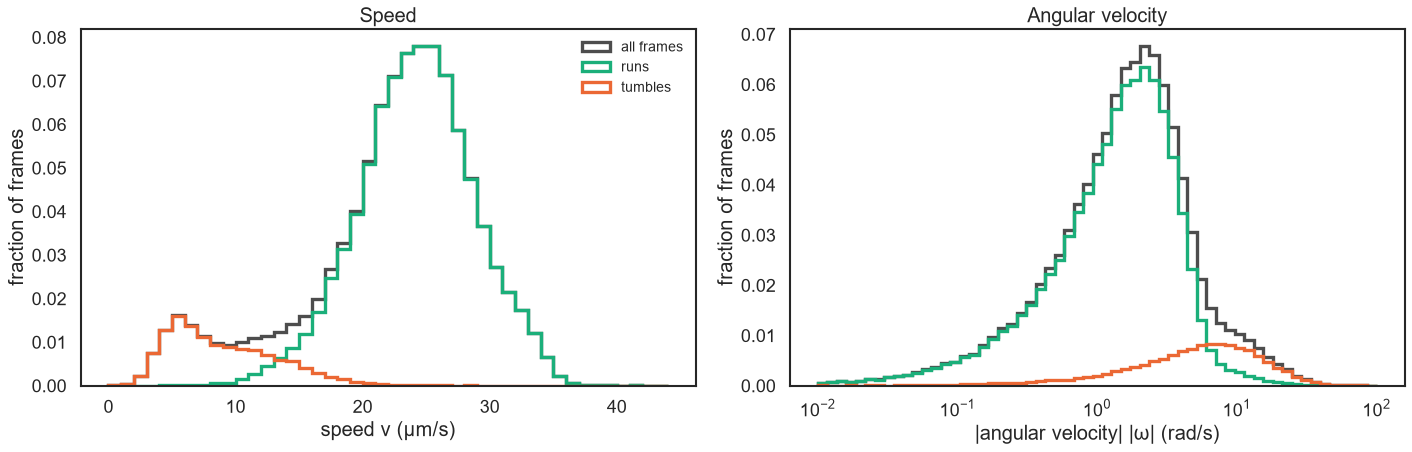

13% of the frames are tumbles


In [8]:
runs, tumbles = kin[kin.state == "run"], kin[kin.state == "tumble"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))
for data, label, color in [(kin, "all frames", "0.3"), (runs, "runs", COLORS["run_tumble"]),
                           (tumbles, "tumbles", COLORS["biased"])]:
    weight = np.full(len(data), 1 / len(kin))         # fractions of all frames, so runs + tumbles = all
    ax1.hist(data["speed"], bins=np.arange(0, 45, 1), weights=weight, histtype="step", lw=3, color=color, label=label)
    ax2.hist(data["omega"].abs(), bins=np.logspace(-2, 2, 60), weights=weight, histtype="step", lw=3, color=color)
ax1.set(xlabel="speed v (µm/s)", ylabel="fraction of frames", title="Speed")
ax2.set(xscale="log", xlabel="|angular velocity| |ω| (rad/s)", ylabel="fraction of frames", title="Angular velocity")
ax1.legend(fontsize="x-small")
fig.tight_layout()
plt.show()
print(f"{len(tumbles) / len(kin):.0%} of the frames are tumbles")

Runs are fast and turn slowly; tumbles are slow and turn fast. But each distribution alone overlaps a lot: a slow run looks like a tumble in speed, and a run with a wobble looks like a tumble in angular velocity.

### 2.4 Differences between individuals: real, or just noise?
Each cell has its own mean speed. Before we call the differences between cells *variability*, we need the **error** of each cell's mean. Speeds in neighboring frames are correlated (we smoothed them!), so the frame-to-frame scatter would underestimate the error. Instead, `an.track_summary` cuts each track into 1 s blocks and uses the scatter of the block means.

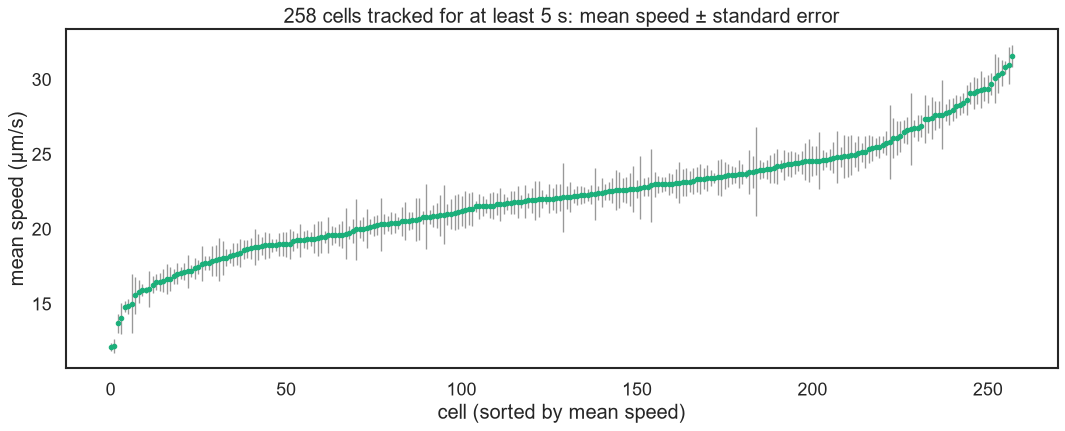

spread of the cell means (standard deviation): 3.6 µm/s
typical error of one cell's mean:              0.8 µm/s


In [9]:
summary = an.track_summary(kin, FPS, block_s=1.0)
summary = summary[summary.duration_s >= 5].sort_values("mean_speed").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(16, 5.5))
ax.errorbar(np.arange(len(summary)), summary["mean_speed"], yerr=summary["sem_speed"], fmt="o", ms=4,
            color=COLORS["run_tumble"], ecolor="0.6", elinewidth=1.2)
ax.set(xlabel="cell (sorted by mean speed)", ylabel="mean speed (µm/s)",
       title=f"{len(summary)} cells tracked for at least 5 s: mean speed ± standard error")
plt.show()

spread, error = summary["mean_speed"].std(), summary["sem_speed"].median()
print(f"spread of the cell means (standard deviation): {spread:.1f} µm/s")
print(f"typical error of one cell's mean:              {error:.1f} µm/s")

The cell means are spread much more widely than their error bars, so the differences between cells are **real**, not noise. (In this dataset each cell was given its own swimming speed, with a standard deviation of `speed_sd` = 4 µm/s.)

## 3 · B · The (v, ω) state space

Speed and angular velocity separate runs and tumbles better **together**. Plot every frame as a point in the plane of angular velocity $\omega$ and speed $v$, and count how many frames fall in each small square (darker = more frames, on a log scale).

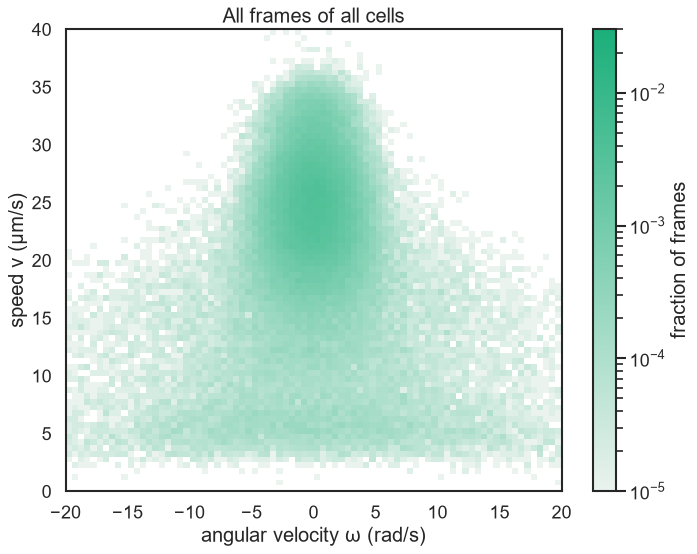

In [10]:
from matplotlib.colors import LogNorm

W_RANGE, V_RANGE = (-20, 20), (0, 40)                 # rad/s, µm/s
BINS = [np.linspace(*W_RANGE, 81), np.linspace(*V_RANGE, 81)]

def state_space(ax, frames, color, title):
    """2D histogram of (omega, speed); frames outside the ranges are left out."""
    counts, w_edges, v_edges = np.histogram2d(frames["omega"], frames["speed"], bins=BINS)
    im = ax.pcolormesh(w_edges, v_edges, counts.T / len(kin), cmap=sns.light_palette(color, as_cmap=True),
                       norm=LogNorm(1e-5, 3e-2), rasterized=True)
    ax.set(xlabel="angular velocity ω (rad/s)", title=title)
    return im

fig, ax = plt.subplots(figsize=(10, 7.5))
im = state_space(ax, kin, COLORS["run_tumble"], "All frames of all cells")
ax.set_ylabel("speed v (µm/s)")
fig.colorbar(im, ax=ax, label="fraction of frames")
plt.show()

The frames fill two regions: a dense band at high speed and small $\omega$, and a diffuse cloud at low speed and large $|\omega|$. **Are these the two states?** We can check with the truth:

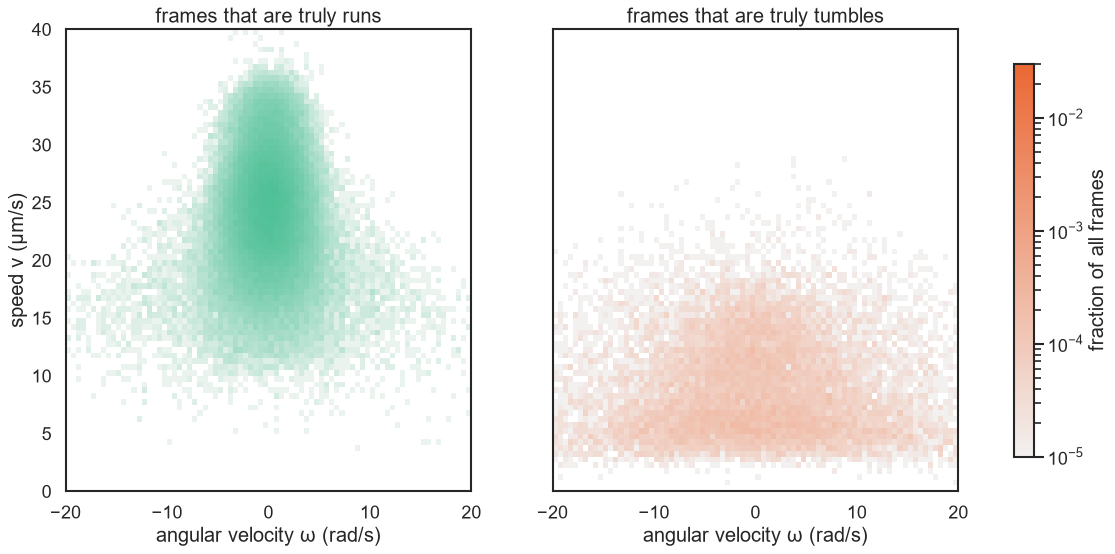

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), sharey=True)
state_space(axes[0], runs, COLORS["run_tumble"], "frames that are truly runs")
im = state_space(axes[1], tumbles, COLORS["biased"], "frames that are truly tumbles")
axes[0].set_ylabel("speed v (µm/s)")
fig.colorbar(im, ax=axes, label="fraction of all frames", shrink=0.85)
plt.show()

Runs and tumbles occupy different regions, but the regions overlap: the start and end of a tumble look like a slow run, and smoothing mixes neighboring frames.

**🔧 Try it: a threshold detector.** Call a frame a tumble if the cell is slower than `V_MAX` **or** turns faster than `W_MIN`. Compare with the truth:
* **recall**: the fraction of true tumble frames that the rule finds;
* **precision**: the fraction of frames called tumbles that are truly tumbles.

Change the thresholds and re-run. Can you get both above 80%? What happens with a different `WINDOW` (section 2.1)? Better state detection is one of the project directions.

recall 95%, precision 68%


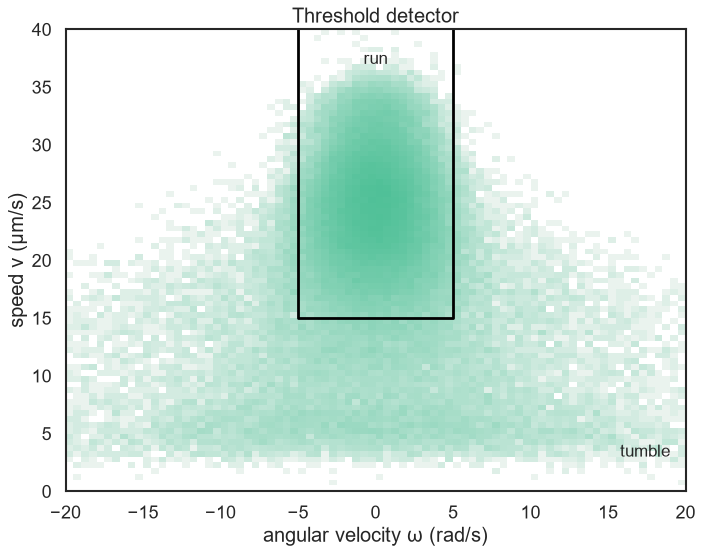

In [12]:
V_MAX = 15.0     # µm/s
W_MIN = 5.0      # rad/s

called = (kin["speed"] < V_MAX) | (kin["omega"].abs() > W_MIN)
true = kin["state"] == "tumble"
recall = (called & true).sum() / true.sum()
precision = (called & true).sum() / called.sum()
print(f"recall {recall:.0%}, precision {precision:.0%}")

fig, ax = plt.subplots(figsize=(10, 7.5))
state_space(ax, kin, COLORS["run_tumble"], "Threshold detector")
ax.plot([-W_MIN, -W_MIN, W_MIN, W_MIN], [V_RANGE[1], V_MAX, V_MAX, V_RANGE[1]], color="k", lw=2.5)
ax.text(0, V_RANGE[1] - 3, "run", ha="center", fontsize="small")
ax.text(W_RANGE[1] - 1, 3, "tumble", ha="right", fontsize="small")
ax.set_ylabel("speed v (µm/s)")
plt.show()

## 4 · C · Correlations: how long does a cell remember?

A run-and-tumble cell keeps its direction during a run and loses it at a tumble. The **autocorrelation** measures this memory: how similar is a quantity now to the same quantity a time $\tau$ later, on average over all cells and times?

* **Velocity autocorrelation:** $C_v(\tau)=\langle\mathbf v(t)\cdot\mathbf v(t+\tau)\rangle$, shown divided by $C_v(0)=\langle|\mathbf v|^2\rangle$.
* **Orientation autocorrelation:** $C_\theta(\tau)=\langle\hat{\mathbf u}(t)\cdot\hat{\mathbf u}(t+\tau)\rangle=\langle\cos[\theta(t+\tau)-\theta(t)]\rangle$, where $\hat{\mathbf u}=\mathbf v/|\mathbf v|$ is the swimming direction. It ignores changes of speed.

`an.autocorrelation` averages over all pairs of frames that are $\tau$ apart in the same track.

**Theory.** For a swimmer that tumbles at a constant rate $\lambda$, turns by angles $\varphi$, and wobbles with rotational diffusion $D_r$, the direction is forgotten exponentially, $C_\theta(\tau)=e^{-\tau/\tau_p}$, with the **persistence time**
$$\tau_p=\frac{1}{\lambda\,(1-\langle\cos\varphi\rangle)+D_r}.$$
Each tumble keeps only a fraction $\langle\cos\varphi\rangle$ of the direction. The formula treats tumbles as instantaneous.

λ = 1.0/s, <cos φ> = 0.31, D_r = 0.15/s  ->  τ_p = 1.19 s


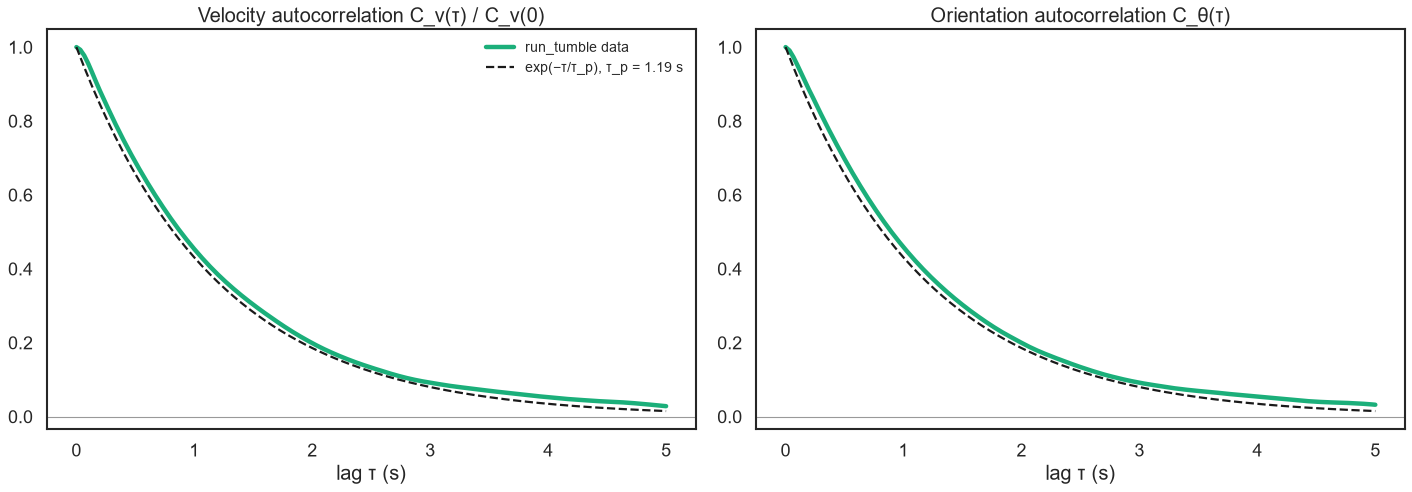

In [13]:
cos_phi = sim.turn_angle_cos(params["turn_angle"])
tau_p = 1 / (params["run_rate"] * (1 - cos_phi) + params["Dr"])
print(f"λ = {params['run_rate']}/s, <cos φ> = {cos_phi:.2f}, D_r = {params['Dr']}/s  ->  τ_p = {tau_p:.2f} s")

MAX_LAG = int(5 * FPS)                                # frames (5 s)
lag_t = np.arange(MAX_LAG + 1) / FPS

def correlations(kin):
    """Normalized velocity and orientation autocorrelations, and the number of frame pairs at each lag."""
    vel = [g[["vx", "vy"]].to_numpy() for _, g in kin.groupby("track_id")]
    unit = [v / np.linalg.norm(v, axis=1, keepdims=True) for v in vel]
    Cv, n_pairs = an.autocorrelation(vel, MAX_LAG)
    Cu, _ = an.autocorrelation(unit, MAX_LAG)
    return Cv / Cv[0], Cu, n_pairs

Cv, Cu, n_pairs = correlations(kin)

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
for ax, C, title in [(axes[0], Cv, "Velocity autocorrelation C_v(τ) / C_v(0)"),
                     (axes[1], Cu, "Orientation autocorrelation C_θ(τ)")]:
    ax.plot(lag_t, C, lw=4, label="run_tumble data", **STYLE["run_tumble"])
    ax.plot(lag_t, np.exp(-lag_t / tau_p), ls="--", label=f"exp(−τ/τ_p), τ_p = {tau_p:.2f} s", **THEORY_KW)
    ax.axhline(0, color="0.6", lw=1)
    ax.set(xlabel="lag τ (s)", title=title)
axes[0].legend(fontsize="x-small")
fig.tight_layout()
plt.show()

The data follow the exponential closely. They lie slightly above it, because real tumbles take time (0.15 s on average here): during a tumble the cell cannot start a new one, and its turn is spread over the tumble instead of happening at once. Both make the cell keep its direction a little longer than the formula predicts.

### 4.1 Comparison: a tumble rate that drifts over time (OU switching)
In real *E. coli* the tumble rate of one cell is not constant. It depends on the level of a signaling protein (CheY-P) that fluctuates slowly. A simple model lets the tumble rate drift:
$$\lambda(t)=\lambda\,e^{\,x(t)-\sigma^2/2},$$
where $x(t)$ is an **Ornstein–Uhlenbeck (OU) process**: a random signal with standard deviation $\sigma$ that forgets its value after a correlation time $\tau_x$. The factor $e^{-\sigma^2/2}$ keeps the average rate equal to $\lambda$.

We simulate cells that are identical to the dataset except for this drift ($\sigma=1$, $\tau_x=10$ s), turn them into a dataset the same way (same track lengths and localization noise), and analyze them exactly as above.

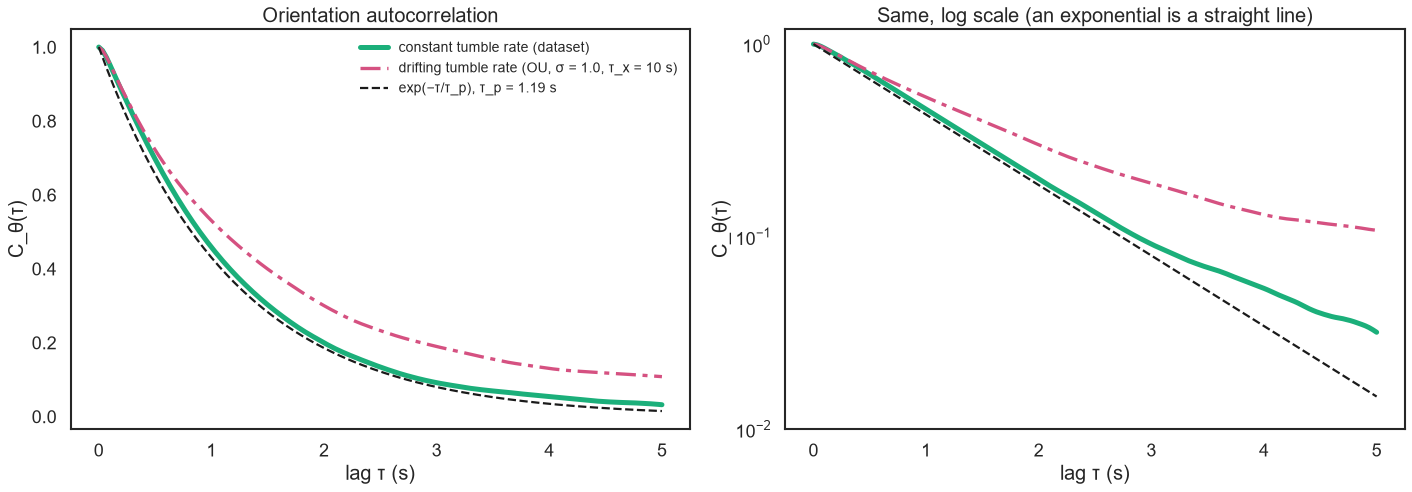

In [14]:
OU_SIGMA, OU_TAU = 1.0, 10.0
positions, states, _ = sim.simulate_run_tumble(400, 40, FPS, rng, **params, ou_sigma=OU_SIGMA, ou_tau=OU_TAU)
df_ou, truth_ou = sim.as_dataset(positions, FPS, rng, states=states, sigma_loc=SIGMA)
kin_ou = an.kinematics(df_ou, FPS, window=WINDOW)
Cv_ou, Cu_ou, _ = correlations(kin_ou)

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
axes[1].set_yscale("log")
for ax in axes:
    ax.plot(lag_t, Cu, lw=4.5, label="constant tumble rate (dataset)", **STYLE["run_tumble"])
    ax.plot(lag_t, Cu_ou, lw=3, label=f"drifting tumble rate (OU, σ = {OU_SIGMA}, τ_x = {OU_TAU:.0f} s)", **STYLE["ou"])
    ax.plot(lag_t, np.exp(-lag_t / tau_p), ls="--", label=f"exp(−τ/τ_p), τ_p = {tau_p:.2f} s", **THEORY_KW)
    ax.set(xlabel="lag τ (s)", ylabel="C_θ(τ)")
axes[0].set(title="Orientation autocorrelation")
axes[1].set(ylim=(1e-2, 1.2), title="Same, log scale (an exponential is a straight line)")
axes[0].legend(fontsize="x-small")
fig.tight_layout()
plt.show()

Cells with a drifting tumble rate remember their direction much longer, although their average tumble rate is the same. In periods when a cell's rate is low, it makes long runs, and these long runs dominate the memory at long lags. On the log scale the curve is no longer straight: a single persistence time no longer describes the population. **Variability within each cell over time changes the behavior of the whole population.** (NB2 shows the same effect in the mean squared displacement.)

> **How far can we trust long lags?** Pairs of frames 5 s apart exist only in tracks longer than 5 s, so long lags rest on fewer, and different, cells than short lags:

In [15]:
for lag in [0, 1, 2, 5]:
    print(f"lag {lag} s: {int(n_pairs[int(lag * FPS)]):>7d} pairs of frames")

lag 0 s:  123855 pairs of frames
lag 1 s:  111855 pairs of frames
lag 2 s:   99855 pairs of frames
lag 5 s:   73505 pairs of frames


## 5 · Summary and questions

* **A · Speeds.** Speeds from frame-to-frame differences are dominated by **localization noise**; at 30 frames per second each velocity component has ~8.5 µm/s of noise. Smoothing reduces the noise but blurs short events, so the window is a trade-off. Differences between cells are only meaningful when they are larger than the **error** of each cell's estimate.
* **B · State space.** In the plane of speed and angular velocity, runs and tumbles occupy different regions. This is the starting point for detecting behavioral states.
* **C · Correlations.** The autocorrelation measures how long a cell remembers its direction. A constant tumble rate gives an exponential decay with persistence time $\tau_p$; a drifting tumble rate gives a longer, non-exponential memory.

**Questions**
1. How would you estimate the localization noise $\sigma$ of a real dataset, where you do not know it? (Hint: NB2, section 7.)
2. Your camera runs at 10 fps instead of 30 fps. What happens to the velocity noise, and to how well you can see tumbles?
3. With the threshold detector, which error is more common: tumbles you miss, or runs you call tumbles? Where in the track do the errors happen?
4. *V. cholerae* reverses instead of tumbling (a turn of about 180°). Where would its reorientations appear in the (v, ω) plane? What would its orientation autocorrelation look like?

**Next:** NB2 (part D) goes from kinematics back to space: the mean squared displacement.